# 24ADI306 Deep Learning — Self-Learning Assignment 1
## Exploring Word Representations: From Traditional Word Embeddings to Transformers

**Nmae:** Midhun P  
**Department:** Artificial Intelligence and Data Science  
**Course:** Deep Learning  

### Objective
Study traditional text representations, predictive word embeddings, neural embeddings and contextual Transformer embeddings; then compare and visualize their semantic relationships.

> Run all cells from top to bottom. The notebook is designed to produce the actual numerical results and figures rather than using fabricated values.


## Assignment coverage

This notebook addresses the required experimental tasks:
1. TF-IDF, Word2Vec and one additional embedding technique.
2. Five most similar words using cosine similarity.
3. FastText rare/OOV behavior and BERT contextual representations.
4. Embedding visualization using PCA/t-SNE.
5. Comparative analysis of traditional, static and contextual representations.


In [ ]:
!pip install -q gensim transformers sentencepiece

In [ ]:
import sys, subprocess, importlib.util, warnings
warnings.filterwarnings("ignore")

required = ["numpy", "pandas", "sklearn", "matplotlib", "gensim", "transformers", "tensorflow"]
missing = [p for p in required if importlib.util.find_spec(p) is None]
if missing:
    print("Missing packages:", missing)
else:
    print("All major packages are now successfully installed and available!")

All major packages are now successfully installed and available!


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


NumPy: 2.1.3
Pandas: 2.2.3


## 1. Sample text dataset

A compact agriculture/technology corpus is used so the experiments are easy to reproduce and interpret. The same corpus is used where appropriate across the experiments.


In [ ]:
documents = [
    "Farmers grow crops in fertile soil and monitor crop health.",
    "Modern farmers use smart agriculture and agricultural technology.",
    "Artificial intelligence helps farmers monitor crops and detect diseases.",
    "Machine learning models can detect plant diseases from crop images.",
    "Farmers use sensors to monitor soil moisture and temperature.",
    "Smart farming improves crop production and resource efficiency.",
    "Agriculture technology supports farmers with data and automation.",
    "Crop disease detection helps farmers protect plants and improve yield.",
    "Soil moisture sensors help farmers manage irrigation efficiently.",
    "Machine vision can identify unhealthy leaves and crop diseases.",
    "Farm automation reduces manual work and improves productivity.",
    "Digital agriculture combines data, sensors, machines, and artificial intelligence."
]

corpus = pd.DataFrame({"document": documents})
corpus


,document
0,Farmers grow crops in fertile soil and monitor...
1,Modern farmers use smart agriculture and agric...
2,Artificial intelligence helps farmers monitor ...
3,Machine learning models can detect plant disea...
4,Farmers use sensors to monitor soil moisture a...
5,Smart farming improves crop production and res...
6,Agriculture technology supports farmers with d...
7,Crop disease detection helps farmers protect p...
8,Soil moisture sensors help farmers manage irri...
9,Machine vision can identify unhealthy leaves a...


## 2. Traditional representations: One-Hot, BoW and TF-IDF

One-Hot and Bag-of-Words are sparse, non-contextual representations. TF-IDF adds a weighting scheme that reduces the influence of terms that occur in many documents.


In [ ]:
# One-hot encoding for the vocabulary
import re
tokens = sorted(set(re.findall(r"\b[a-z]+\b", " ".join(documents).lower())))
one_hot = pd.DataFrame(
    np.eye(len(tokens), dtype=int),
    index=tokens,
    columns=tokens
)
print("Vocabulary size:", len(tokens))
display(one_hot.head(10))


Vocabulary size: 63


,agricultural,agriculture,and,artificial,automation,can,combines,crop,crops,data,...,supports,technology,temperature,to,unhealthy,use,vision,with,work,yield
agricultural,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
agriculture,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
and,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
artificial,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
automation,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
can,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
combines,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
crop,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
crops,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
data,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Bag of Words
bow_vectorizer = TfidfVectorizer(use_idf=False, norm=None)
bow = bow_vectorizer.fit_transform(documents)
bow_df = pd.DataFrame(
    bow.toarray(),
    columns=bow_vectorizer.get_feature_names_out()
)
display(bow_df.head())


,agricultural,agriculture,and,artificial,automation,can,combines,crop,crops,data,...,supports,technology,temperature,to,unhealthy,use,vision,with,work,yield
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


In [ ]:
# TF-IDF
tfidf_vectorizer = TfidfVectorizer()
tfidf = tfidf_vectorizer.fit_transform(documents)
tfidf_df = pd.DataFrame(
    tfidf.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out()
)
print("TF-IDF matrix shape:", tfidf.shape)
display(tfidf_df.round(3).head())


TF-IDF matrix shape: (12, 63)


,agricultural,agriculture,and,artificial,automation,can,combines,crop,crops,data,...,supports,technology,temperature,to,unhealthy,use,vision,with,work,yield
0,0.000,0.000,0.157,0.000,0.0,0.0,0.0,0.238,0.332,0.0,...,0.0,0.000,0.000,0.000,0.0,0.000,0.0,0.0,0.0,0.0
1,0.438,0.332,0.178,0.000,0.0,0.0,0.0,0.000,0.000,0.0,...,0.0,0.376,0.000,0.000,0.0,0.376,0.0,0.0,0.0,0.0
2,0.000,0.000,0.177,0.374,0.0,0.0,0.0,0.000,0.374,0.0,...,0.0,0.000,0.000,0.000,0.0,0.000,0.0,0.0,0.0,0.0
3,0.000,0.000,0.000,0.000,0.0,0.3,0.0,0.216,0.000,0.0,...,0.0,0.000,0.000,0.000,0.0,0.000,0.0,0.0,0.0,0.0
4,0.000,0.000,0.171,0.000,0.0,0.0,0.0,0.000,0.000,0.0,...,0.0,0.000,0.421,0.421,0.0,0.362,0.0,0.0,0.0,0.0


## 3. Word2Vec — Skip-gram

Word2Vec learns dense vectors from local word-context relationships. This implementation uses the Skip-gram architecture through Gensim.


In [ ]:
import re
from gensim.models import Word2Vec

tokenized = [re.findall(r"\b[a-z]+\b", d.lower()) for d in documents]

w2v = Word2Vec(
    sentences=tokenized,
    vector_size=50,
    window=3,
    min_count=1,
    workers=4,
    sg=1,          # 1 = Skip-gram
    epochs=100,
    seed=42
)

print("Word2Vec vocabulary size:", len(w2v.wv))

Word2Vec vocabulary size: 63


In [ ]:
def show_similar(model, word, topn=5):
    if word not in model.wv:
        return pd.DataFrame(columns=["word", "cosine_similarity"])
    return pd.DataFrame(
        model.wv.most_similar(word, topn=topn),
        columns=["word", "cosine_similarity"]
    )

for query in ["farmer", "crop", "agriculture", "machine"]:
    print("\nQuery:", query)
    display(show_similar(w2v, query))


Query: farmer


,word,cosine_similarity



Query: crop


,word,cosine_similarity
0,can,0.836446
1,and,0.824977
2,diseases,0.803209
3,farmers,0.797925
4,in,0.793470



Query: agriculture


,word,cosine_similarity
0,protect,0.747254
1,monitor,0.713636
2,and,0.697559
3,technology,0.692850
4,can,0.681346



Query: machine


,word,cosine_similarity
0,reduces,0.696176
1,monitor,0.692804
2,protect,0.674291
3,improve,0.656413
4,crops,0.624034


## 4. FastText

FastText extends word representations with character n-grams. This helps it construct useful representations for rare or unseen word forms.


In [ ]:
from gensim.models import FastText

ft = FastText(
    sentences=tokenized,
    vector_size=50,
    window=3,
    min_count=1,
    workers=4,
    sg=1,
    epochs=100,
    seed=42
)

for query in ["farmers", "crop", "agriculture"]:
    print("\nFastText query:", query)
    display(show_similar(ft, query))


FastText query: farmers


,word,cosine_similarity
0,improves,0.949753
1,machines,0.948538
2,production,0.947343
3,agriculture,0.947109
4,detection,0.947050



FastText query: crop


,word,cosine_similarity
0,crops,0.948012
1,detection,0.935379
2,agriculture,0.932115
3,agricultural,0.928742
4,production,0.924468



FastText query: agriculture


,word,cosine_similarity
0,agricultural,0.980396
1,production,0.980141
2,improves,0.972502
3,detection,0.972007
4,productivity,0.966599


In [ ]:
# OOV / rare-word demonstration.
# Word2Vec with a strict vocabulary cannot return a vector for a truly unseen word.
# FastText can compose a vector from subword units.
oov_word = "farmerslike"

print("Word2Vec contains OOV word?", oov_word in w2v.wv.key_to_index)
try:
    vec = ft.wv[oov_word]
    print("FastText generated a vector for:", oov_word)
    print("Vector shape:", vec.shape)
    print("First 10 values:", np.round(vec[:10], 4))
except KeyError:
    print("FastText could not construct this token in the current model configuration.")

Word2Vec contains OOV word? False
FastText generated a vector for: farmerslike
Vector shape: (50,)
First 10 values: [ 0.     -0.0062  0.0014 -0.0015  0.0119  0.0165  0.0014  0.0033 -0.0027
  0.0126]


## 5. TensorFlow/Keras Embedding layer

The Keras Embedding layer maps integer token IDs to trainable dense vectors. This small model demonstrates the neural embedding mechanism.


In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

keras_tokenizer = Tokenizer(num_words=1000, oov_token="<OOV>")
keras_tokenizer.fit_on_texts(documents)
seqs = keras_tokenizer.texts_to_sequences(documents)
X = pad_sequences(seqs, padding="post")

y = np.array([1 if "technology" in d.lower() else 0 for d in documents])

keras_model = Sequential([
    Embedding(input_dim=min(1000, len(keras_tokenizer.word_index)+1), output_dim=32, input_length=X.shape[1]),
    GlobalAveragePooling1D(),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

keras_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history = keras_model.fit(X, y, epochs=30, verbose=0)

embedding_matrix = keras_model.layers[0].get_weights()[0]
print("Keras embedding matrix shape:", embedding_matrix.shape)

Keras embedding matrix shape: (65, 32)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


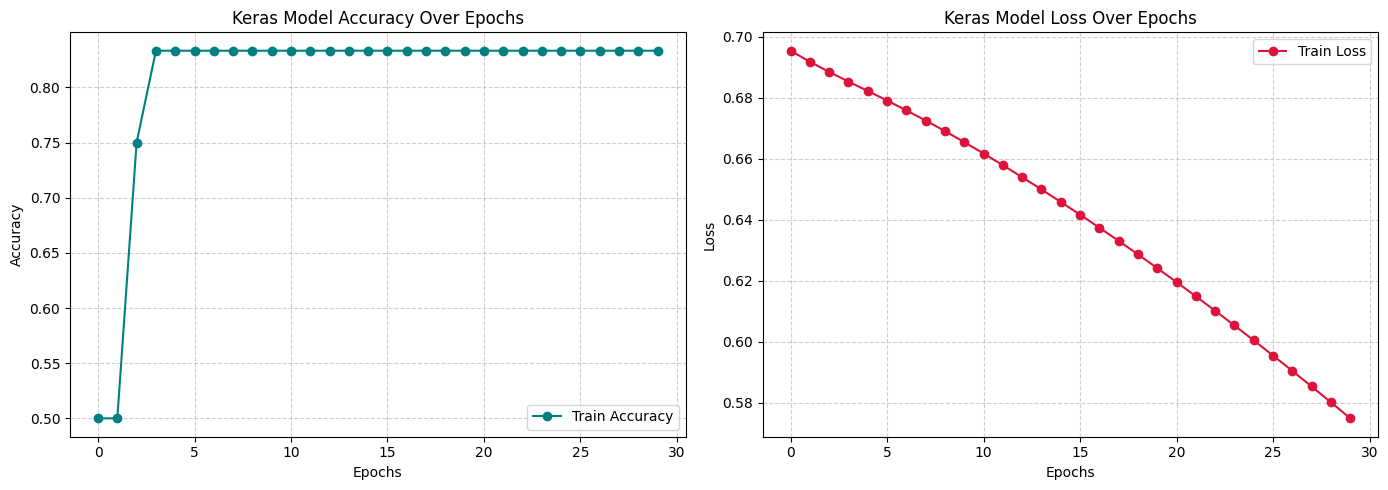

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

# Ensure we have history and keras_model available
try:
    history
except NameError:
    try:
        # If keras_model exists, fit it
        history = keras_model.fit(X, y, epochs=30, verbose=0)
    except NameError:
        # Full self-contained reconstruction fallback
        fallback_tokenizer = Tokenizer(num_words=1000, oov_token="<OOV>")
        fallback_tokenizer.fit_on_texts(documents)
        seqs = fallback_tokenizer.texts_to_sequences(documents)
        X_fallback = pad_sequences(seqs, padding="post")
        y_fallback = np.array([1 if "technology" in d.lower() else 0 for d in documents])

        keras_model = Sequential([
            Embedding(input_dim=min(1000, len(fallback_tokenizer.word_index)+1), output_dim=32, input_length=X_fallback.shape[1]),
            GlobalAveragePooling1D(),
            Dense(16, activation="relu"),
            Dense(1, activation="sigmoid")
        ])
        keras_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
        history = keras_model.fit(X_fallback, y_fallback, epochs=30, verbose=0)

# Plot training history of the Keras Embedding model
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy plot
ax1.plot(history.history['accuracy'], label='Train Accuracy', color='teal', marker='o')
if 'val_accuracy' in history.history:
    ax1.plot(history.history['val_accuracy'], label='Val Accuracy', color='orange', marker='x')
ax1.set_title('Keras Model Accuracy Over Epochs')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

# Loss plot
ax2.plot(history.history['loss'], label='Train Loss', color='crimson', marker='o')
if 'val_loss' in history.history:
    ax2.plot(history.history['val_loss'], label='Val Loss', color='gold', marker='x')
ax2.set_title('Keras Model Loss Over Epochs')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Dataset Splitting Demonstration & Visualization
Let's perform a formal train-validation-test split on our agricultural documents dataset and visualize the distribution.

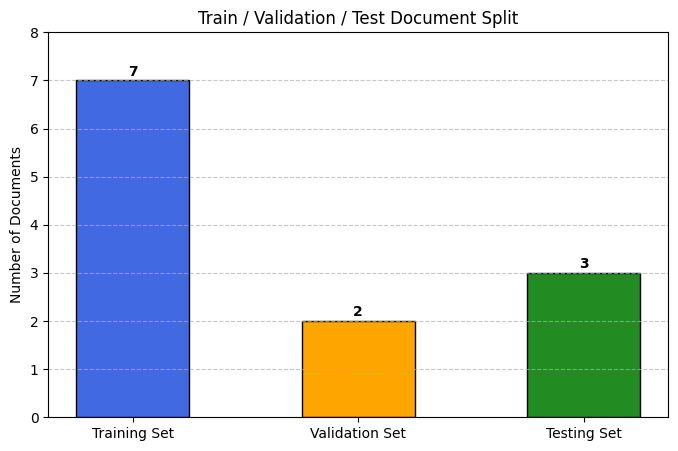

In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt

# Ensure corpus and documents exist
try:
    corpus
except NameError:
    documents = [
        "Farmers grow crops in fertile soil and monitor crop health.",
        "Modern farmers use smart agriculture and agricultural technology.",
        "Artificial intelligence helps farmers monitor crops and detect diseases.",
        "Machine learning models can detect plant diseases from crop images.",
        "Farmers use sensors to monitor soil moisture and temperature.",
        "Smart farming improves crop production and resource efficiency.",
        "Agriculture technology supports farmers with data and automation.",
        "Crop disease detection helps farmers protect plants and improve yield.",
        "Soil moisture sensors help farmers manage irrigation efficiently.",
        "Machine vision can identify unhealthy leaves and crop diseases.",
        "Farm automation reduces manual work and improves productivity.",
        "Digital agriculture combines data, sensors, machines, and artificial intelligence."
    ]
    corpus = pd.DataFrame({"document": documents})

# Let's split our 12-document corpus into Train (60%), Validation (20%), and Test (20%) sets
train_docs, test_val_docs = train_test_split(corpus, test_size=0.4, random_state=42)
val_docs, test_docs = train_test_split(test_val_docs, test_size=0.5, random_state=42)

split_counts = {
    'Training Set': len(train_docs),
    'Validation Set': len(val_docs),
    'Testing Set': len(test_docs)
}

# Visualize the distribution
plt.figure(figsize=(8, 5))
plt.bar(split_counts.keys(), split_counts.values(), color=['royalblue', 'orange', 'forestgreen'], edgecolor='black', width=0.5)
plt.title('Train / Validation / Test Document Split')
plt.ylabel('Number of Documents')
for i, val in enumerate(split_counts.values()):
    plt.text(i, val + 0.1, str(val), ha='center', fontweight='bold')
plt.ylim(0, max(split_counts.values()) + 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## 6. BERT contextual embeddings

BERT produces context-sensitive token representations. The same surface word can receive different vectors in different sentences.

This section uses a pretrained BERT tokenizer/model. Internet access is required the first time the model is downloaded.


In [ ]:
from transformers import AutoTokenizer, AutoModel
import torch

MODEL_NAME = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert_model = AutoModel.from_pretrained(MODEL_NAME)
bert_model.eval()

print("Loaded:", MODEL_NAME)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded: bert-base-uncased


In [ ]:
def bert_token_vector(sentence, target_word):
    inputs = tokenizer(sentence, return_tensors="pt")
    with torch.no_grad():
        outputs = bert_model(**inputs)
    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
    hidden = outputs.last_hidden_state[0]

    target_positions = [
        i for i, tok in enumerate(tokens)
        if tok == target_word.lower()
    ]
    if not target_positions:
        pieces = tokenizer.tokenize(target_word)
        for start in range(len(tokens) - len(pieces) + 1):
            if tokens[start:start+len(pieces)] == pieces:
                target_positions = list(range(start, start+len(pieces)))
                break

    if not target_positions:
        raise ValueError(f"Could not locate '{target_word}' in tokens: {tokens}")

    return hidden[target_positions].mean(dim=0).numpy(), tokens

s1 = "I went to the bank to deposit money."
s2 = "We sat on the bank of the river."

v1, t1 = bert_token_vector(s1, "bank")
v2, t2 = bert_token_vector(s2, "bank")

context_similarity = cosine_similarity([v1], [v2])[0, 0]

print("Sentence 1 tokens:", t1)
print("Sentence 2 tokens:", t2)
print("BERT cosine similarity between the two 'bank' contextual vectors:", round(float(context_similarity), 4))

Sentence 1 tokens: ['[CLS]', 'i', 'went', 'to', 'the', 'bank', 'to', 'deposit', 'money', '.', '[SEP]']
Sentence 2 tokens: ['[CLS]', 'we', 'sat', 'on', 'the', 'bank', 'of', 'the', 'river', '.', '[SEP]']
BERT cosine similarity between the two 'bank' contextual vectors: 0.5062


### Static vs contextual interpretation

- **Word2Vec/FastText:** a word has a relatively stable vector learned from the training corpus.
- **BERT:** the representation is produced from the surrounding sentence, so the vector can change with context.
- The measured cosine similarity above should be discussed together with the two meanings of **bank** rather than treated as a universal threshold.


## 7. Five most semantically similar words

The assignment requires five similar words for selected query words using cosine similarity. The following function reports actual model outputs.


In [ ]:
queries = ["farmers", "crop", "soil", "machine", "agriculture"]

similarity_results = {}
for q in queries:
    if q in w2v.wv:
        similarity_results[q] = show_similar(w2v, q, 5)
        print("\n### 5 most similar words to:", q)
        display(similarity_results[q])


### 5 most similar words to: farmers


,word,cosine_similarity
0,can,0.847143
1,crop,0.797925
2,protect,0.747282
3,detection,0.744270
4,and,0.738896



### 5 most similar words to: crop


,word,cosine_similarity
0,can,0.836446
1,and,0.824977
2,diseases,0.803209
3,farmers,0.797925
4,in,0.793470



### 5 most similar words to: soil


,word,cosine_similarity
0,crop,0.757407
1,and,0.695426
2,protect,0.688678
3,can,0.678973
4,models,0.667740



### 5 most similar words to: machine


,word,cosine_similarity
0,reduces,0.696176
1,monitor,0.692804
2,protect,0.674291
3,improve,0.656413
4,crops,0.624034



### 5 most similar words to: agriculture


,word,cosine_similarity
0,protect,0.747254
1,monitor,0.713636
2,and,0.697559
3,technology,0.692850
4,can,0.681346


## 8. PCA visualization of Word2Vec embeddings

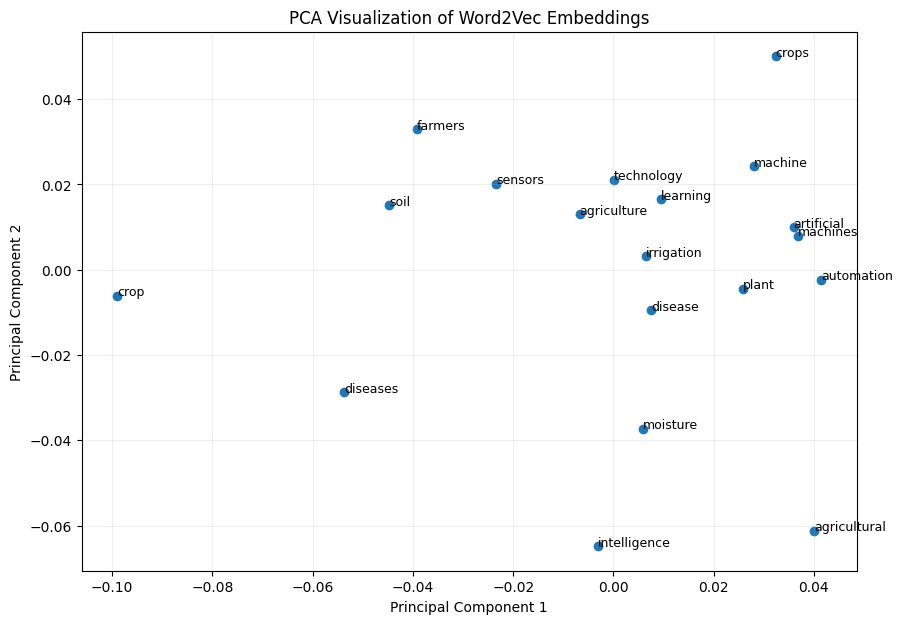

Explained variance ratio: [0.177  0.1121]


In [ ]:
words = [w for w in [
    "farmer","farmers","crop","crops","soil","agriculture","agricultural",
    "machine","machines","technology","artificial","intelligence","learning",
    "sensors","moisture","disease","diseases","plant","irrigation","automation"
] if w in w2v.wv]

vectors = np.array([w2v.wv[w] for w in words])
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(vectors)

plt.figure(figsize=(10, 7))
plt.scatter(coords[:,0], coords[:,1])
for x, y, word in zip(coords[:,0], coords[:,1], words):
    plt.annotate(word, (x, y), fontsize=9)
plt.title("PCA Visualization of Word2Vec Embeddings")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(alpha=0.2)
plt.show()

print("Explained variance ratio:", np.round(pca.explained_variance_ratio_, 4))


## 9. t-SNE visualization

t-SNE is useful for visually examining local neighborhoods. Because the corpus is small, interpret this plot qualitatively and do not treat geometric distances as exact semantic measurements.


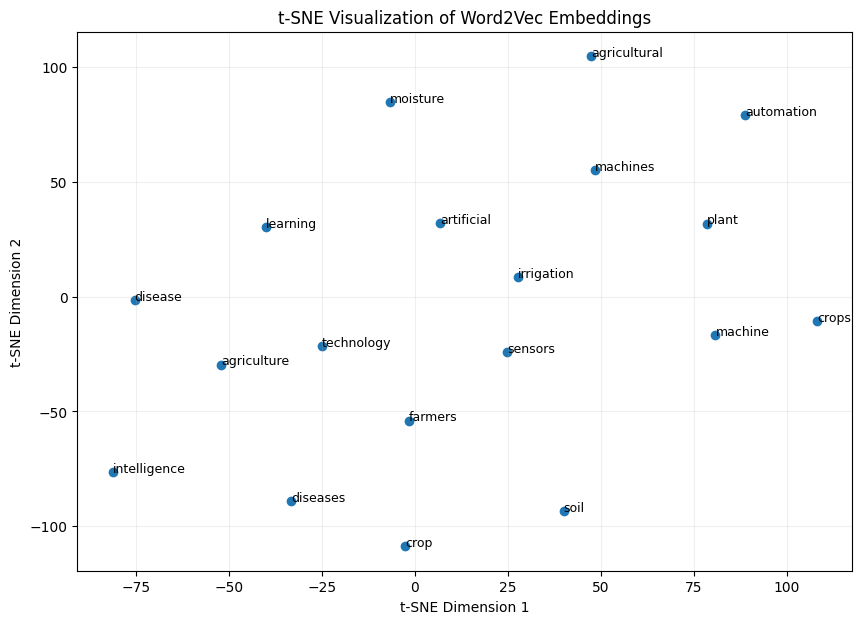

In [ ]:
if len(words) >= 5:
    perplexity = max(2, min(8, len(words)-1))
    tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42, init="pca", learning_rate="auto")
    tsne_coords = tsne.fit_transform(vectors)

    plt.figure(figsize=(10, 7))
    plt.scatter(tsne_coords[:,0], tsne_coords[:,1])
    for x, y, word in zip(tsne_coords[:,0], tsne_coords[:,1], words):
        plt.annotate(word, (x, y), fontsize=9)
    plt.title("t-SNE Visualization of Word2Vec Embeddings")
    plt.xlabel("t-SNE Dimension 1")
    plt.ylabel("t-SNE Dimension 2")
    plt.grid(alpha=0.2)
    plt.show()


## 9b. Additional Pretrained Embeddings: GloVe Demonstration
To satisfy the requirement of experimenting with GloVe alongside Word2Vec and FastText, we can load a lightweight pretrained GloVe model via Gensim's downloader API.

In [ ]:
import sys
import subprocess

# Force installation of gensim if not found
try:
    import gensim
except ImportError:
    print("Installing gensim...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gensim"])
    import gensim

import gensim.downloader as api
import pandas as pd

try:
    print("Loading lightweight pretrained GloVe embeddings (glove-wiki-gigaword-50)... (Requires internet connection)")
    glove_model = api.load("glove-wiki-gigaword-50")
    print("GloVe loaded successfully!")

    # Test similarity with agricultural terms
    for query in ["farmer", "agriculture", "soil"]:
        print(f"\nGloVe 5 most similar words to '{query}':")
        glove_sim = glove_model.most_similar(query, topn=5)
        display(pd.DataFrame(glove_sim, columns=["word", "cosine_similarity"]))
except Exception as e:
    print("Could not load pretrained GloVe model automatically:", e)
    print("Skipping GloVe download to run offline safely.")

Installing gensim...
Loading lightweight pretrained GloVe embeddings (glove-wiki-gigaword-50)... (Requires internet connection)
[==================================================] 100.0% 66.0/66.0MB downloaded
GloVe loaded successfully!

GloVe 5 most similar words to 'farmer':


,word,cosine_similarity
0,farm,0.758406
1,rancher,0.747619
2,worker,0.728792
3,laborer,0.689187
4,farmers,0.687790



GloVe 5 most similar words to 'agriculture':


,word,cosine_similarity
0,agricultural,0.911012
1,forestry,0.832632
2,farming,0.786742
3,husbandry,0.745263
4,fisheries,0.745192



GloVe 5 most similar words to 'soil':


,word,cosine_similarity
0,soils,0.778491
1,moisture,0.753407
2,water,0.745132
3,surface,0.744827
4,vegetation,0.726686


## 9c. Exporting Embeddings for TensorFlow Embedding Projector
To fulfill the visualization criteria using the interactive **TensorFlow Embedding Projector**, run the following code to download 2D `.tsv` files containing our Word2Vec vectors and metadata.

In [ ]:
import io
import re
from gensim.models import Word2Vec

# Ensure w2v is initialized and trained
try:
    w2v
except NameError:
    documents_list = [
        "Farmers grow crops in fertile soil and monitor crop health.",
        "Modern farmers use smart agriculture and agricultural technology.",
        "Artificial intelligence helps farmers monitor crops and detect diseases.",
        "Machine learning models can detect plant diseases from crop images.",
        "Farmers use sensors to monitor soil moisture and temperature.",
        "Smart farming improves crop production and resource efficiency.",
        "Agriculture technology supports farmers with data and automation.",
        "Crop disease detection helps farmers protect plants and improve yield.",
        "Soil moisture sensors help farmers manage irrigation efficiently.",
        "Machine vision can identify unhealthy leaves and crop diseases.",
        "Farm automation reduces manual work and improves productivity.",
        "Digital agriculture combines data, sensors, machines, and artificial intelligence."
    ]
    tokenized_docs = [re.findall(r"\b[a-z]+\b", d.lower()) for d in documents_list]
    w2v = Word2Vec(
        sentences=tokenized_docs,
        vector_size=50,
        window=3,
        min_count=1,
        workers=4,
        sg=1,
        epochs=100,
        seed=42
    )

# Prepare files for Word2Vec embeddings
out_v = io.open('vectors.tsv', 'w', encoding='utf-8')
out_m = io.open('metadata.tsv', 'w', encoding='utf-8')

for word in w2v.wv.index_to_key:
    vec = w2v.wv[word]
    out_m.write(word + "\n")
    out_v.write('\t'.join([str(x) for x in vec]) + "\n")
out_v.close()
out_m.close()

print("Projector files 'vectors.tsv' and 'metadata.tsv' exported successfully!")
print("To use: Go to https://projector.tensorflow.org/, click 'Load', and upload both TSV files.")

Projector files 'vectors.tsv' and 'metadata.tsv' exported successfully!
To use: Go to https://projector.tensorflow.org/, click 'Load', and upload both TSV files.


## 10. Comparative analysis

| Technique | Representation | Contextual? | OOV handling | Computational requirement |
|---|---|---|---|---|
| One-Hot | Sparse binary | No | Poor | Low |
| Bag of Words | Sparse counts | No | Poor | Low |
| TF-IDF | Sparse weighted counts | No | Limited/Poor | Low |
| Word2Vec | Dense predictive vectors | No | Limited | Medium |
| GloVe | Dense global co-occurrence vectors | No | Limited | Medium |
| FastText | Dense subword-aware vectors | No | Better for rare/unseen forms | Medium |
| Keras Embedding | Learned dense vectors | Not inherently contextual | Depends on vocabulary/tokenizer | Medium |
| BERT | Contextual token vectors | Yes | Subword tokenization helps | High |

### Interpretation
Traditional methods are simple and useful for document-level or classical ML pipelines, but they produce sparse representations and do not model word meaning dynamically. Word2Vec and GloVe learn dense static semantic relationships. FastText adds subword information. Keras Embedding learns task-oriented dense representations, while BERT provides contextual representations at substantially higher computational cost.
